# NB05_eda — Thống kê mô tả & EDA (mục 5.1)
**Cách chạy:** mở trên Colab (loại thời gian chạy: CPU) → Runtime → Run all.
- Đầu vào: `data/coffee_shop_sales_raw.csv`, tải theo ID từ thư mục Drive của nhóm.
- Trường dẫn xuất (giờ, thứ, tháng, doanh thu) tính theo đúng quy tắc NB01 (mục 3.4.2).
- Đầu ra: 6 hình PNG trong `figures/` (Hình 5.1–5.6) và `figures/so_lieu_5_1.md` (số liệu dẫn trong báo cáo).

In [9]:
# ==== 0. CẤU HÌNH ====
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

RAW_FILE_ID = '14t3nlw6cO1ju0qG7HXzWONE6XOaC9B9m'      # data/coffee_shop_sales_raw.csv
try:
    import google.colab  # noqa: F401
    WORK = '/content'
except ImportError:
    WORK = os.environ.get('NB05_BASE', '.')
RAW = os.path.join(WORK, 'data', 'coffee_shop_sales_raw.csv')
FIG = os.path.join(WORK, 'figures')
os.makedirs(os.path.dirname(RAW), exist_ok=True); os.makedirs(FIG, exist_ok=True)
if not os.path.exists(RAW):
    import gdown
    gdown.download(id=RAW_FILE_ID, output=RAW, quiet=False)

# Bảng màu: 3 màu đầu của bảng phân loại đã kiểm tra mù màu; chữ và lưới dùng màu trung tính
STORE_COLOR = {'Astoria': '#2a78d6', "Hell's Kitchen": '#eb6834', 'Lower Manhattan': '#1baf7a'}
INK, INK2, GRID, MUTED = '#0b0b0b', '#52514e', '#e4e3df', '#b9b8b2'
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'figure.dpi': 110, 'savefig.dpi': 200,
    'savefig.bbox': 'tight', 'figure.facecolor': 'white',
})
def vn(x, d=0):
    """Định dạng số kiểu Việt Nam: 1.234,5"""
    return f'{x:,.{d}f}'.replace(',', '#').replace('.', ',').replace('#', '.')
NOTES = []   # số liệu dẫn trong báo cáo

In [10]:
# ==== 1. ĐỌC DỮ LIỆU & TRƯỜNG DẪN XUẤT ====
df = pd.read_csv(RAW, dtype={'transaction_time': str})
df['product_detail'] = df['product_detail'].str.strip()
df['date'] = pd.to_datetime(df['transaction_date'])
df['hour'] = pd.to_datetime(df['transaction_time'].str.strip(), format='%H:%M:%S').dt.hour
df['dow'] = df['date'].dt.dayofweek + 1                     # 1 = Thứ Hai ... 7 = Chủ nhật
df['month'] = df['date'].dt.month
df['revenue'] = (df['transaction_qty'] * df['unit_price']).round(2)
assert len(df) == 149_116 and round(df['revenue'].sum(), 2) == 698_812.33
print(df.shape, df['date'].min().date(), df['date'].max().date())

(149116, 16) 2023-01-01 2023-06-30


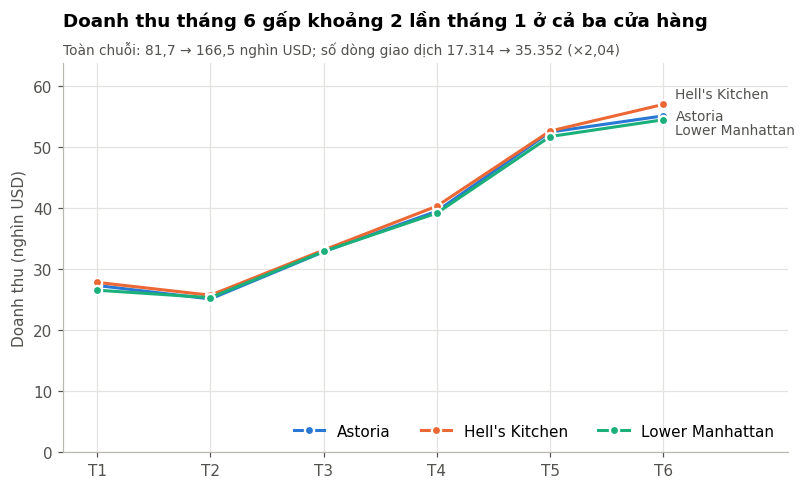

In [11]:
# ==== 2. HÌNH 5.1 — DOANH THU THEO THÁNG × CỬA HÀNG (5.1.1) ====
m = df.groupby('month').agg(lines=('transaction_id', 'size'), rev=('revenue', 'sum'), days=('date', 'nunique'))
m['ticket'] = m['rev'] / m['lines']
ms = df.pivot_table(index='month', columns='store_location', values='revenue', aggfunc='sum') / 1000
months = ['T1', 'T2', 'T3', 'T4', 'T5', 'T6']

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for s, c in STORE_COLOR.items():
    ax.plot(months, ms[s], color=c, lw=2, marker='o', ms=6, mec='white', mew=1.5, label=s)
    ax.annotate(s, (5, ms[s].iloc[-1]), xytext=(8, {'Astoria': 0, "Hell's Kitchen": 7, 'Lower Manhattan': -7}[s]),
                textcoords='offset points', va='center', color=INK2, fontsize=9)
ax.set_ylabel('Doanh thu (nghìn USD)'); ax.set_ylim(0, ms.max().max() * 1.12)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: vn(v)))
ax.set_xlim(-0.3, 6.1)
ax.set_title('Doanh thu tháng 6 gấp khoảng 2 lần tháng 1 ở cả ba cửa hàng', loc='left', pad=24)
ax.text(0, 1.015, f'Toàn chuỗi: {vn(m.rev.iloc[0]/1000,1)} → {vn(m.rev.iloc[-1]/1000,1)} nghìn USD; '
        f'số dòng giao dịch {vn(m.lines.iloc[0])} → {vn(m.lines.iloc[-1])} (×{vn(m.lines.iloc[-1]/m.lines.iloc[0],2)})',
        transform=ax.transAxes, color=INK2, fontsize=9, va='bottom')
ax.legend(loc='lower right', frameon=False, ncol=3)
fig.savefig(os.path.join(FIG, 'hinh_5_1_doanh_thu_thang_cua_hang.png')); plt.show()

NOTES += [
    f"Doanh thu toàn chuỗi T1→T6: {vn(m.rev.iloc[0],2)} → {vn(m.rev.iloc[-1],2)} USD (×{vn(m.rev.iloc[-1]/m.rev.iloc[0],3)})",
    f"Số dòng giao dịch T1→T6: {vn(m.lines.iloc[0])} → {vn(m.lines.iloc[-1])} (×{vn(m.lines.iloc[-1]/m.lines.iloc[0],3)})",
    f"Giá trị bình quân một dòng theo tháng (USD): {', '.join(vn(v,2) for v in m.ticket)}",
    f"Số dòng/ngày T1, T2: {vn(m.lines.iloc[0]/31,1)}, {vn(m.lines.iloc[1]/28,1)}",
    'Hệ số T6/T1 theo cửa hàng: ' + ', '.join(f'{s} ×{vn(ms[s].iloc[-1]/ms[s].iloc[0],3)}' for s in STORE_COLOR),
    'Doanh thu 6 tháng theo cửa hàng (USD): ' + ', '.join(f'{s} {vn(v,2)}' for s, v in df.groupby('store_location').revenue.sum().items()),
]

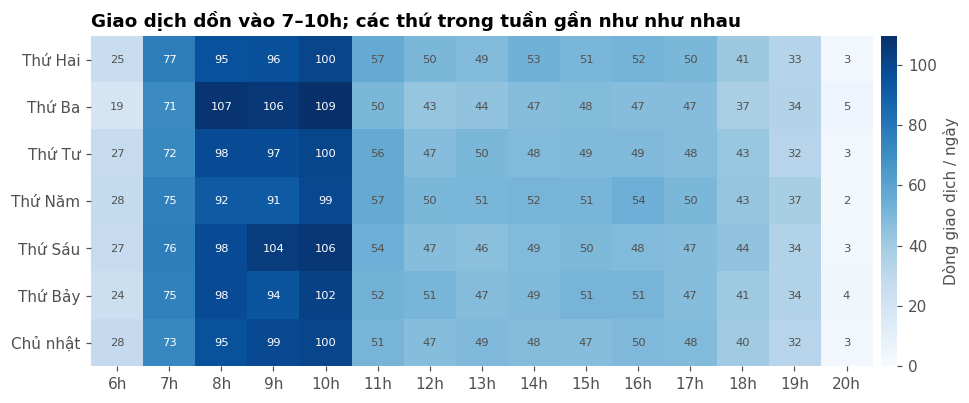

In [12]:
# ==== 3. HÌNH 5.2 — SỐ DÒNG GIAO DỊCH BÌNH QUÂN/NGÀY THEO GIỜ × THỨ (5.1.2) ====
# Chia cho số ngày của từng thứ (Thứ Bảy có 25 ngày, các thứ khác 26) để so sánh công bằng
ndays = df.groupby('dow')['date'].nunique()
hm = df.pivot_table(index='dow', columns='hour', values='transaction_id', aggfunc='size').fillna(0)
hm = hm.div(ndays, axis=0)
dow_lbl = ['Thứ Hai', 'Thứ Ba', 'Thứ Tư', 'Thứ Năm', 'Thứ Sáu', 'Thứ Bảy', 'Chủ nhật']

fig, ax = plt.subplots(figsize=(9.5, 3.9))
im = ax.imshow(hm.values, cmap='Blues', aspect='auto', vmin=0)
ax.set_xticks(range(hm.shape[1]), [f'{h}h' for h in hm.columns]); ax.set_yticks(range(7), dow_lbl)
ax.grid(False); [sp.set_visible(False) for sp in ax.spines.values()]
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        ax.text(j, i, vn(v), ha='center', va='center', fontsize=7.5, color='white' if v > hm.values.max() * 0.55 else INK2)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.outline.set_visible(False)
cb.set_label('Dòng giao dịch / ngày', color=INK2)
ax.set_title('Giao dịch dồn vào 7–10h; các thứ trong tuần gần như như nhau', loc='left')
fig.savefig(os.path.join(FIG, 'hinh_5_2_heatmap_gio_thu.png')); plt.show()

h = df.groupby('hour').size(); hs = h / h.sum() * 100
dpd = df.groupby('dow').size() / ndays
NOTES += [
    f"Tỷ trọng 7–10h: {vn(hs.loc[7:10].sum(),1)}% số dòng; giờ cao nhất {h.idxmax()}h ({vn(hs.max(),1)}%); 11–17h mỗi giờ {vn(hs.loc[11:17].min(),1)}–{vn(hs.loc[11:17].max(),1)}%",
    f"Ô cao nhất: {vn(hm.values.max(),1)} dòng/ngày; số dòng/ngày theo thứ: {vn(dpd.min(),1)}–{vn(dpd.max(),1)} (chênh {vn((dpd.max()/dpd.min()-1)*100,1)}%)",
]

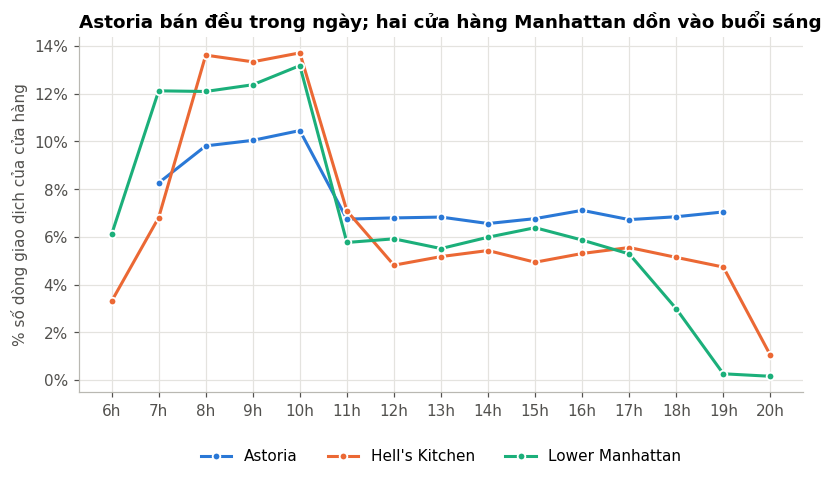

In [13]:
# ==== 4. HÌNH 5.3 — HỒ SƠ THEO GIỜ CỦA TỪNG CỬA HÀNG (5.1.2) ====
ph = df.pivot_table(index='hour', columns='store_location', values='transaction_id', aggfunc='size').fillna(0)
ph = ph / ph.sum() * 100
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for s, c in STORE_COLOR.items():
    y = ph[s].replace(0, np.nan)
    ax.plot(ph.index, y, color=c, lw=2, marker='o', ms=5, mec='white', mew=1.2, label=s)
ax.set_xticks(ph.index, [f'{x}h' for x in ph.index]); ax.set_ylabel('% số dòng giao dịch của cửa hàng')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: vn(v) + '%'))
ax.set_title('Astoria bán đều trong ngày; hai cửa hàng Manhattan dồn vào buổi sáng', loc='left')
ax.legend(frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.12))
fig.savefig(os.path.join(FIG, 'hinh_5_3_gio_theo_cua_hang.png')); plt.show()
am = {s: ph[s].loc[7:10].sum() for s in STORE_COLOR}
rng_ = df.groupby('store_location').hour.agg(['min', 'max'])
NOTES += ['Tỷ trọng 7–10h theo cửa hàng: ' + ', '.join(f'{s} {vn(v,1)}%' for s, v in am.items()),
          'Giờ mở–đóng theo dữ liệu: ' + ', '.join(f"{s} {r['min']}h–{r['max']}h" for s, r in rng_.iterrows())]

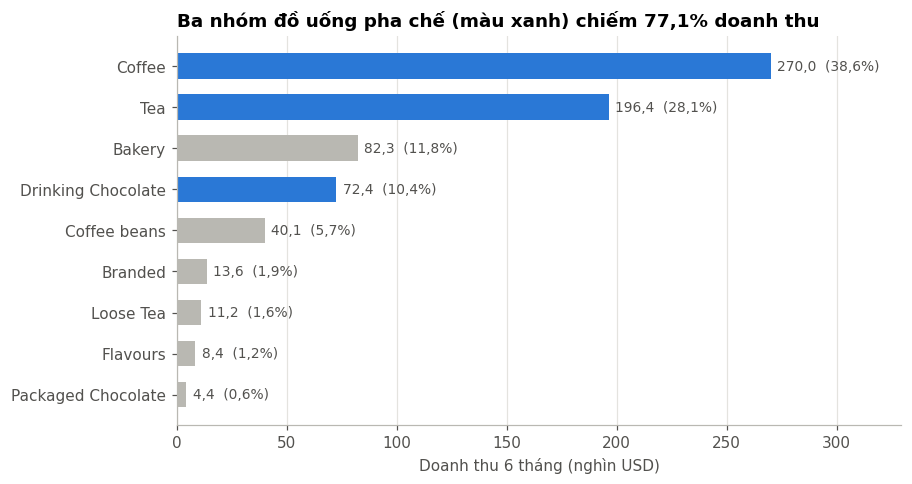

In [14]:
# ==== 5. HÌNH 5.4 — CƠ CẤU DOANH THU THEO NHÓM SẢN PHẨM (5.1.3) ====
c = df.groupby('product_category').agg(rev=('revenue', 'sum'), lines=('transaction_id', 'size')).sort_values('rev')
c['pct'] = c['rev'] / c['rev'].sum() * 100
DRINKS = ['Coffee', 'Tea', 'Drinking Chocolate']
fig, ax = plt.subplots(figsize=(8.5, 4.6))
bars = ax.barh(c.index, c['rev'] / 1000, color=['#2a78d6' if k in DRINKS else MUTED for k in c.index], height=0.62)
for b, (k, r) in zip(bars, c.iterrows()):
    ax.text(b.get_width() + 3, b.get_y() + b.get_height() / 2, f"{vn(r.rev/1000,1)}  ({vn(r.pct,1)}%)",
            va='center', color=INK2, fontsize=9)
ax.set_xlabel('Doanh thu 6 tháng (nghìn USD)'); ax.grid(axis='y', visible=False)
ax.set_xlim(0, c['rev'].max() / 1000 * 1.22)
share = c.loc[DRINKS, 'pct'].sum()
ax.set_title(f'Ba nhóm đồ uống pha chế (màu xanh) chiếm {vn(share,1)}% doanh thu', loc='left')
fig.savefig(os.path.join(FIG, 'hinh_5_4_co_cau_nhom_san_pham.png')); plt.show()
cb_ = c.loc['Coffee beans']
NOTES += [f"Đồ uống pha chế: {vn(share,2)}% doanh thu; Coffee {vn(c.loc['Coffee','pct'],2)}%, Tea {vn(c.loc['Tea','pct'],2)}%",
          f"Coffee beans: {vn(cb_.lines/c.lines.sum()*100,2)}% số dòng nhưng {vn(cb_.pct,2)}% doanh thu; Flavours {vn(c.loc['Flavours','lines']/c.lines.sum()*100,2)}% số dòng, {vn(c.loc['Flavours','pct'],2)}% doanh thu"]

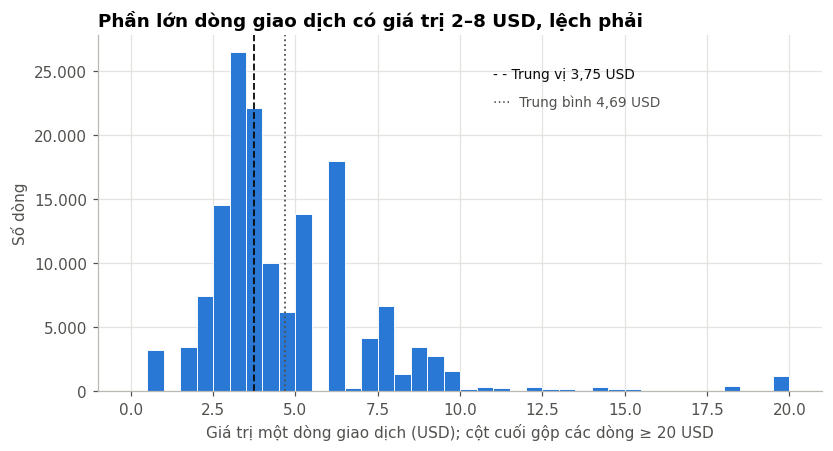

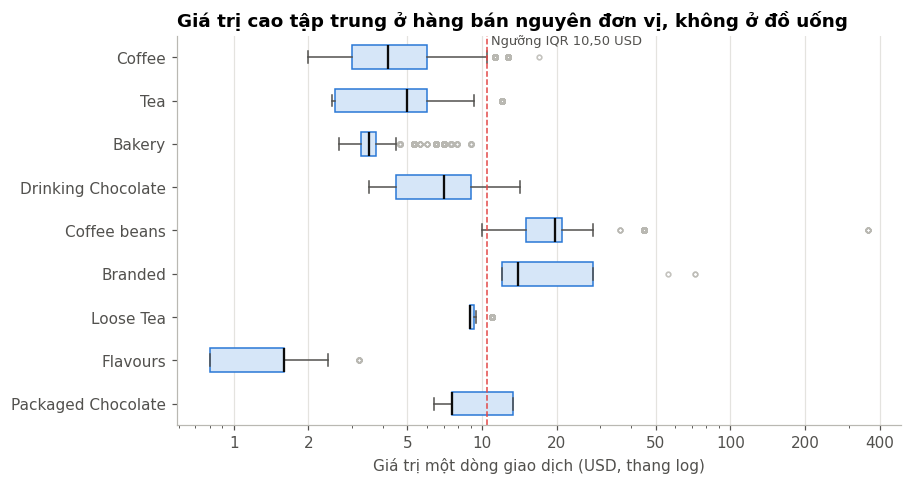

In [15]:
# ==== 6. HÌNH 5.5–5.6 — PHÂN PHỐI GIÁ TRỊ DÒNG GIAO DỊCH (5.1.3) ====
r = df['revenue']; q1, med, q3 = r.quantile([.25, .5, .75]); upper = q3 + 1.5 * (q3 - q1)
CAP = 20
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(r.clip(upper=CAP), bins=np.arange(0, CAP + 0.5, 0.5), color='#2a78d6', edgecolor='white', linewidth=0.6)
ax.axvline(med, color=INK, lw=1.2, ls='--'); ax.axvline(r.mean(), color=INK2, lw=1.2, ls=':')
ax.text(11, ax.get_ylim()[1] * 0.88, f'- - Trung vị {vn(med,2)} USD', color=INK, fontsize=9)
ax.text(11, ax.get_ylim()[1] * 0.80, f'····  Trung bình {vn(r.mean(),2)} USD', color=INK2, fontsize=9)
ax.set_xlabel(f'Giá trị một dòng giao dịch (USD); cột cuối gộp các dòng ≥ {CAP} USD')
ax.set_ylabel('Số dòng'); ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: vn(v)))
ax.set_title('Phần lớn dòng giao dịch có giá trị 2–8 USD, lệch phải', loc='left')
fig.savefig(os.path.join(FIG, 'hinh_5_5_histogram_gia_tri_dong.png')); plt.show()

order = c.sort_values('rev', ascending=False).index[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.boxplot([df.loc[df.product_category == k, 'revenue'] for k in order], vert=False, widths=0.55,
           patch_artist=True, boxprops=dict(facecolor='#d6e6f8', edgecolor='#2a78d6'),
           medianprops=dict(color=INK, lw=1.5), whiskerprops=dict(color=INK2), capprops=dict(color=INK2),
           flierprops=dict(marker='o', ms=3, mfc='none', mec=MUTED, alpha=0.6))
ax.set_yticks(range(1, len(order) + 1), order)   # đặt nhãn riêng: tương thích mọi phiên bản matplotlib
ax.set_xscale('log'); ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: vn(v, 0 if v >= 1 else 1)))
ax.set_xticks([1, 2, 5, 10, 20, 50, 100, 200, 400])
ax.axvline(upper, color='#e34948', lw=1, ls='--'); ax.text(upper * 1.04, len(order) + 0.3, f'Ngưỡng IQR {vn(upper,2)} USD', color=INK2, fontsize=8.5)
ax.set_xlabel('Giá trị một dòng giao dịch (USD, thang log)'); ax.grid(axis='y', visible=False)
ax.set_title('Giá trị cao tập trung ở hàng bán nguyên đơn vị, không ở đồ uống', loc='left')
fig.savefig(os.path.join(FIG, 'hinh_5_6_boxplot_nhom_san_pham.png')); plt.show()
NOTES += [f"Giá trị dòng: trung vị {vn(med,2)}, trung bình {vn(r.mean(),2)}, Q1 {vn(q1,2)}, Q3 {vn(q3,2)}, P95 {vn(r.quantile(.95),2)}, P99 {vn(r.quantile(.99),2)}, max {vn(r.max(),2)} USD",
          f"Tỷ lệ dòng 2–8 USD: {vn(((r>=2)&(r<=8)).mean()*100,1)}%; dòng > ngưỡng IQR {vn(upper,2)}: {vn((r>upper).sum())} ({vn((r>upper).mean()*100,2)}%)",
          f"Dòng giá trị lớn nhất: {df.loc[r.idxmax(),'product_detail']} × {df.loc[r.idxmax(),'transaction_qty']} = {vn(r.max(),2)} USD"]

In [16]:
# ==== 7. SỐ LIỆU CHO BÁO CÁO ====
txt = '\n'.join('- ' + n for n in NOTES)
open(os.path.join(FIG, 'so_lieu_5_1.md'), 'w', encoding='utf-8').write(txt)
print(txt)

- Doanh thu toàn chuỗi T1→T6: 81.677,74 → 166.485,88 USD (×2,038)
- Số dòng giao dịch T1→T6: 17.314 → 35.352 (×2,042)
- Giá trị bình quân một dòng theo tháng (USD): 4,72, 4,65, 4,66, 4,69, 4,67, 4,71
- Số dòng/ngày T1, T2: 558,5, 584,2
- Hệ số T6/T1 theo cửa hàng: Astoria ×2,017, Hell's Kitchen ×2,047, Lower Manhattan ×2,051
- Doanh thu 6 tháng theo cửa hàng (USD): Astoria 232.243,91, Hell's Kitchen 236.511,17, Lower Manhattan 230.057,25
- Tỷ trọng 7–10h: 45,2% số dòng; giờ cao nhất 10h (12,4%); 11–17h mỗi giờ 5,8–6,5%
- Ô cao nhất: 109,5 dòng/ngày; số dòng/ngày theo thứ: 811,4–834,7 (chênh 2,9%)
- Tỷ trọng 7–10h theo cửa hàng: Astoria 38,6%, Hell's Kitchen 47,5%, Lower Manhattan 49,8%
- Giờ mở–đóng theo dữ liệu: Astoria 7h–19h, Hell's Kitchen 6h–20h, Lower Manhattan 6h–20h
- Đồ uống pha chế: 77,10% doanh thu; Coffee 38,63%, Tea 28,11%
- Coffee beans: 1,18% số dòng nhưng 5,74% doanh thu; Flavours 4,55% số dòng, 1,20% doanh thu
- Giá trị dòng: trung vị 3,75, trung bình 4,69, Q1 3,00, Q3